# Lab 6, Task 2A: Experimental 2 by 2 MIMO

Generate orthogonal sounding waveforms, collect two synchronized receiver channels, estimate the channel matrix, and compare MIMO and SISO capacity.

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Image

def find_lab_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "support" / "lab6_dsp.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the Lab 6 folder tree")

LAB_ROOT = find_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
import lab6_dsp as lab
import lab6_tools as tools
print("Lab folder:", LAB_ROOT.name)


Lab folder: Lab6


## Prepare finite dual-channel waveforms

In [2]:
tx_gains_db = (40, 45, 50)
rx_gain_db = 60
tx_subdevice = "A:0 A:1"
rx_subdevice = "A:0 A:1"
tx_antenna = "TX/RX"
rx_antenna = "RX2"
prep_root = LAB_ROOT/'work'
prepared = tools.prepare_hardware_experiment(
    prep_root/'waveforms', prep_root/'captures', tx_gains_db, rx_gain_db,
    tx_subdevice, rx_subdevice, tx_antenna, rx_antenna
)
print('TX files:', Path(prepared['tx0_path']).name, Path(prepared['tx1_path']).name)
print('Radio configuration:', prepared['summary']['experiment'])
print('Bytes per TX file:', prepared['bytes_per_tx_file'])

TX files: lab6_tx_ch0_c64.dat lab6_tx_ch1_c64.dat
Radio configuration: {'tx_gains_db': [40, 45, 50], 'rx_gain_db': 60.0, 'noise_samples_per_channel': 250000, 'tx_subdevice': 'A:0 A:1', 'rx_subdevice': 'A:0 A:1', 'tx_antenna': 'TX/RX', 'rx_antenna': 'RX2'}
Bytes per TX file: 24388608


In [7]:
from pathlib import Path
import sys

LAB_ROOT = Path("/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab6")
sys.path.insert(0, str(LAB_ROOT / "support"))

import lab6_tools as tools

output_dir = LAB_ROOT / "expected_figures"

results = tools.generate_simulation(output_dir)

print("Figures generated successfully!")
for file in sorted(output_dir.glob("*.png")):
    print(file.name)

Figures generated successfully!
task1_diversity_by_method.png
task1_diversity_comparison.png
task1_mimo_capacity_and_estimation.png
task2_waveform_schedule.png


## GNU Radio capture

Use the provided transmitter, receiver monitor, and finite receiver flowgraphs as directed in the manual. Run the receiver before the transmitter. Save one noise-only record and one dual-channel record at each TX gain.

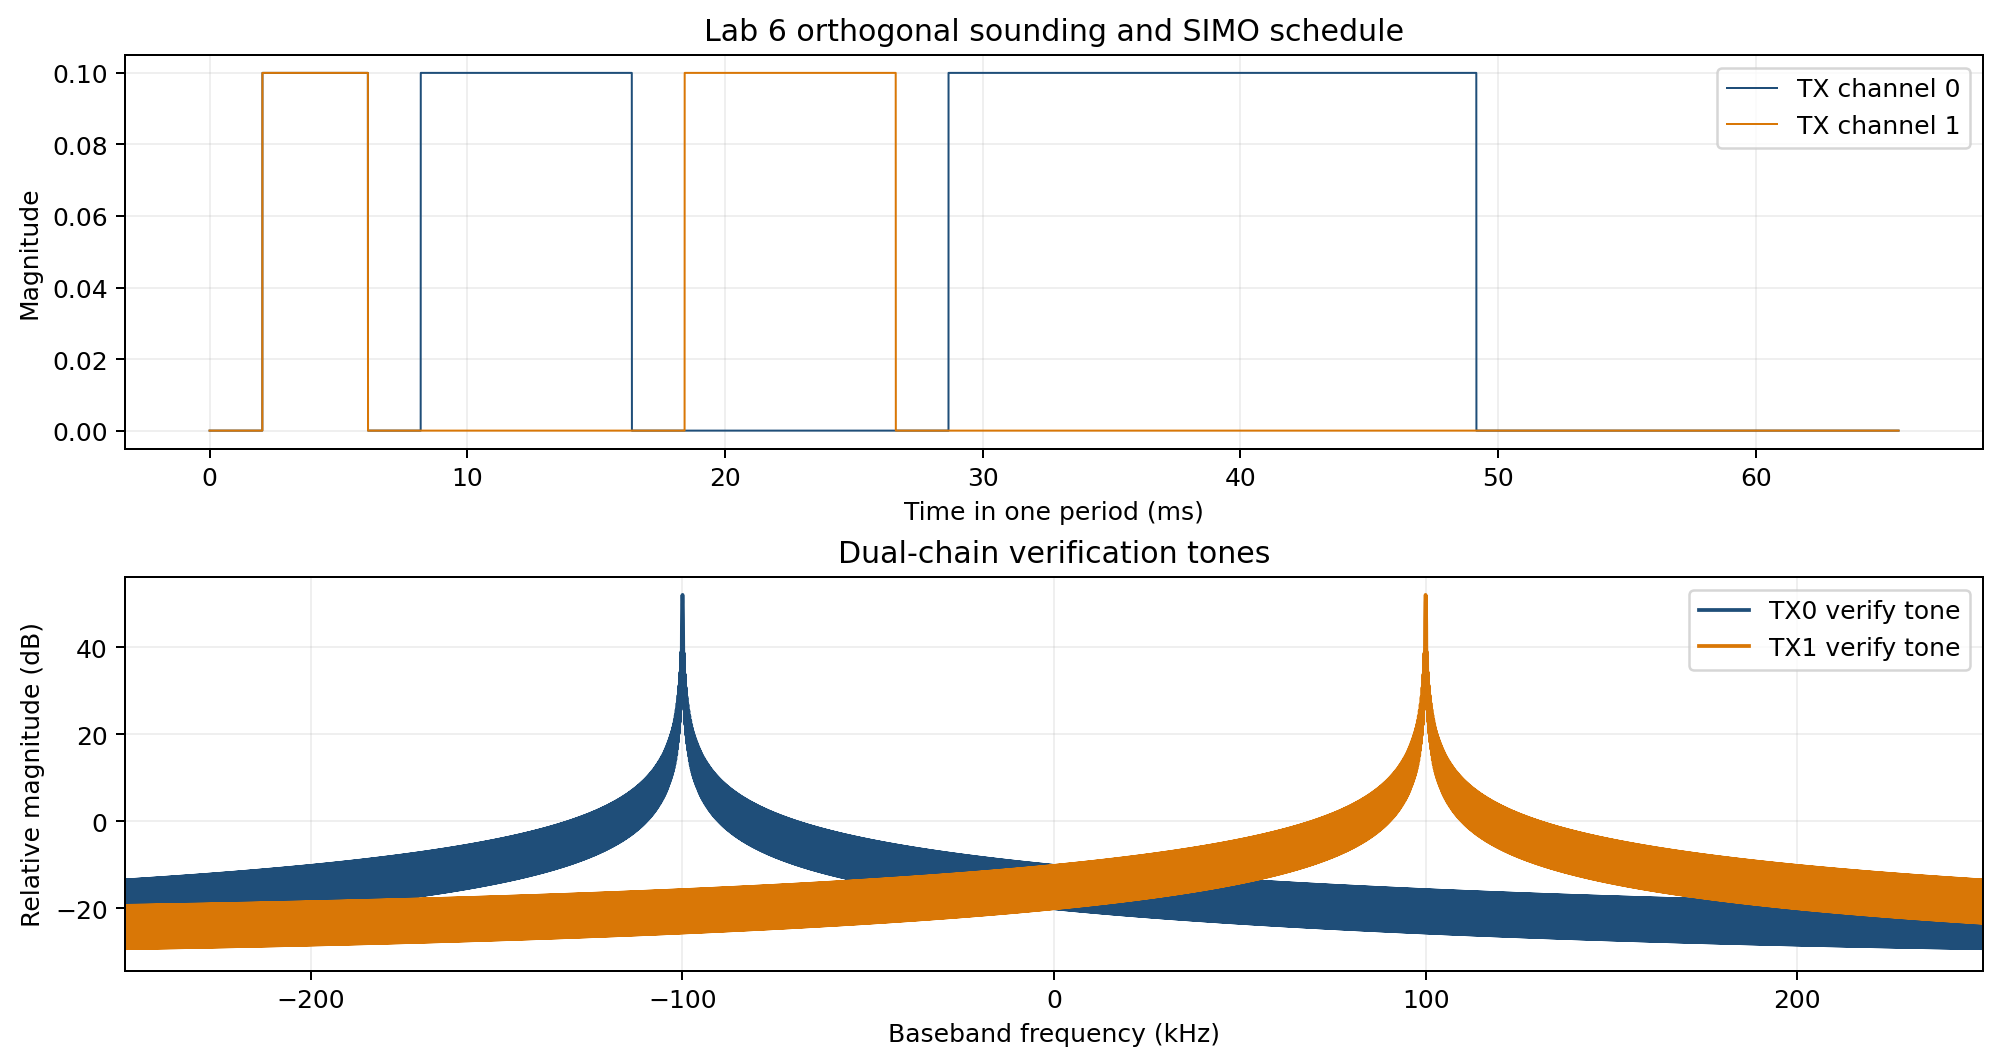

In [11]:
display(Image(filename=str(LAB_ROOT/'expected_figures/task2_waveform_schedule.png'), width=900))

## Analyze the captures

The library performs acquisition, CFO correction, plotting, and repeated-frame aggregation. You are responsible for checking the matrix calculation and interpreting the result.

In [19]:
capture_dir = LAB_ROOT/'work/captures'
figure_dir = LAB_ROOT/'work/figures'
hardware = tools.analyze_hardware(capture_dir, figure_dir)
for gain, values in hardware['gains'].items():
    print(gain, 'frames', values['analyzed_frames'], 'capacity', round(values['mimo_capacity_mean_bps_hz'],3), 'condition', round(values['condition_number_mean'],3))

tx40 frames 15 capacity 14.959 condition 31741.055
tx45 frames 15 capacity 16.577 condition 78221.874
tx50 frames 9 capacity 18.217 condition 49239.04


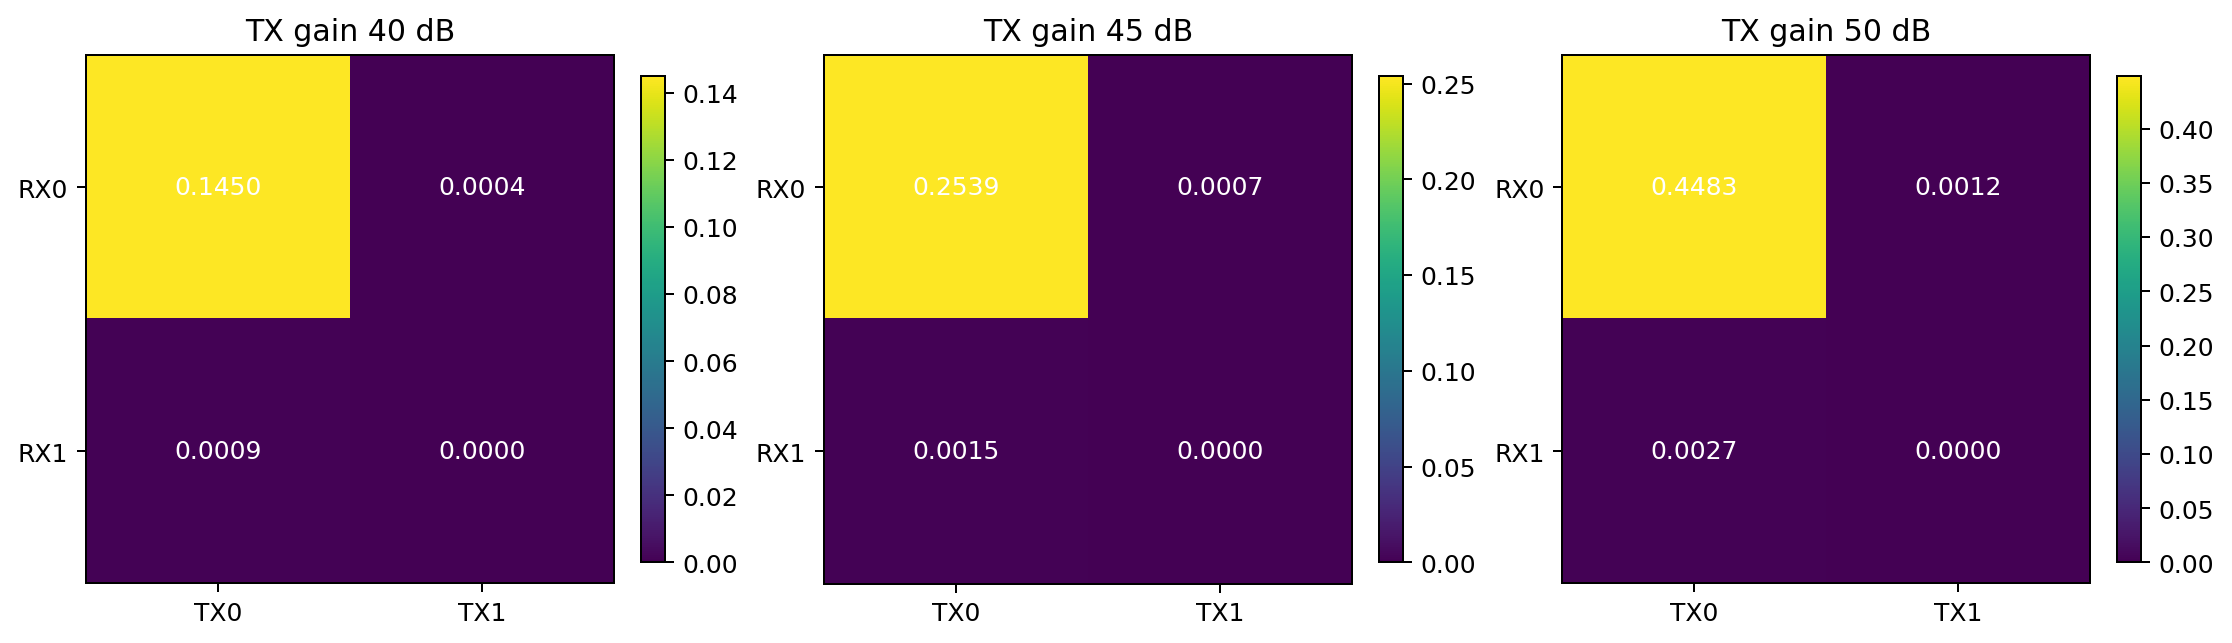

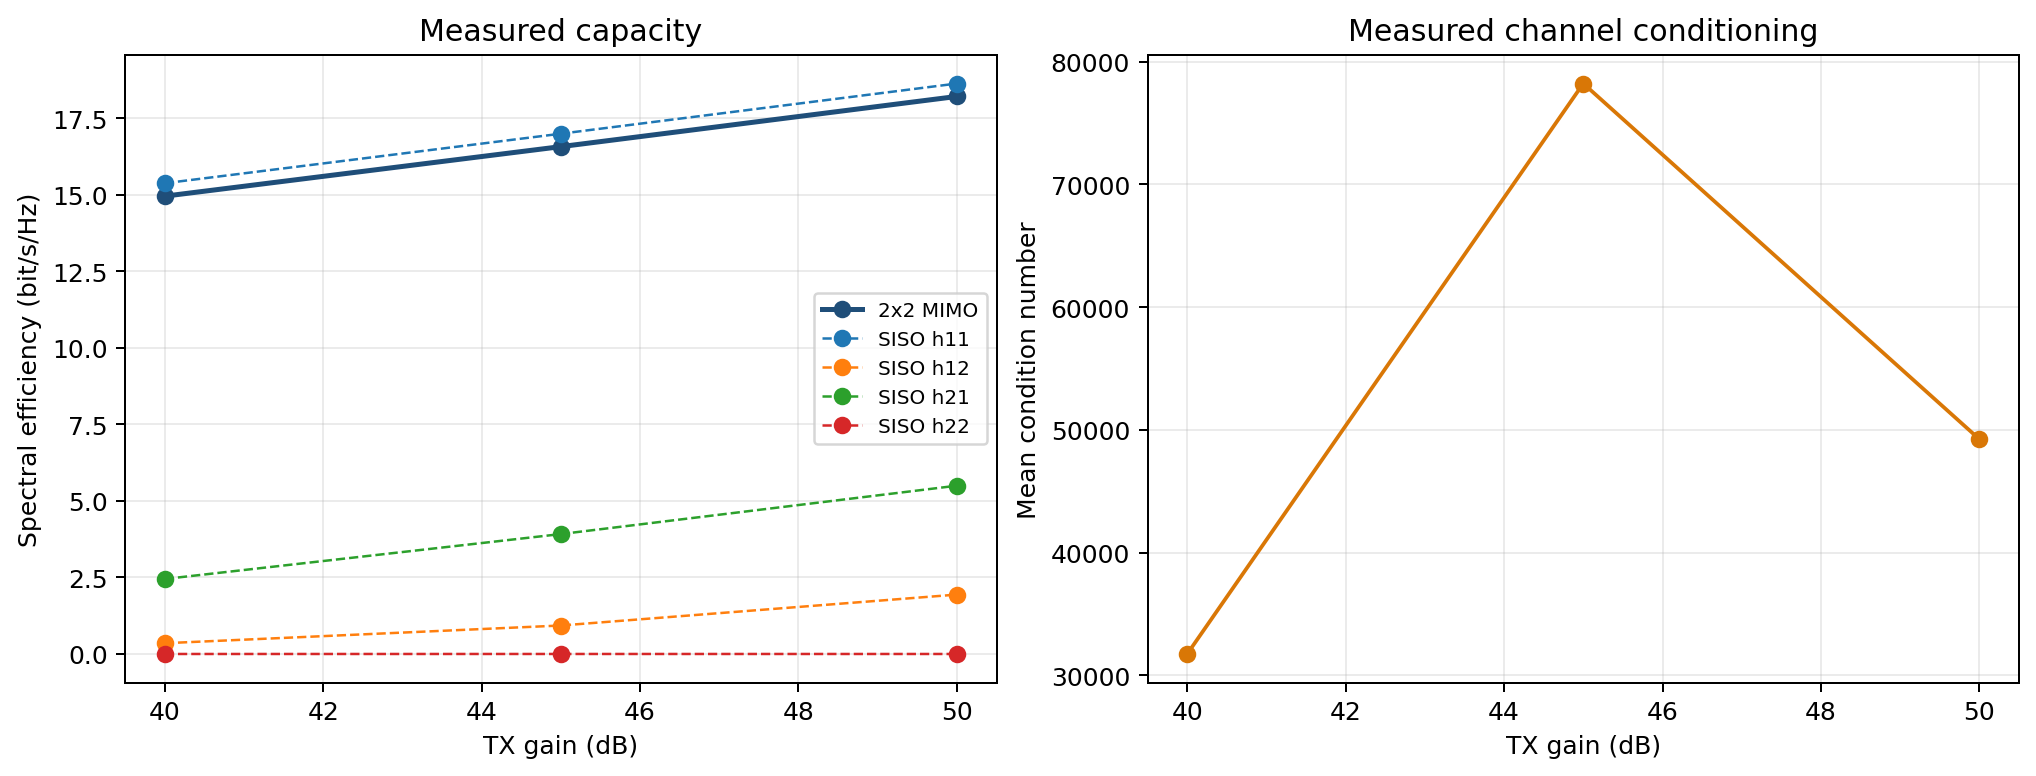

In [20]:
display(Image(filename=str(figure_dir/'task2_hardware_channel_matrices.png'), width=1000))
display(Image(filename=str(figure_dir/'task2_hardware_capacity.png'), width=900))

## Check one capacity calculation

In [21]:
middle = hardware['gains'][f'tx{tx_gains_db[1]}']
h_real = np.array(middle['mimo_channel_reference']['real'])
h_imag = np.array(middle['mimo_channel_reference']['imag'])
h_hat = h_real + 1j*h_imag
noise = np.mean(hardware['noise_variance'])
# STUDENT: use digital pilot energy 0.1^2 and two transmitters to form total linear SNR, then compute capacity.
rho = 2 * (0.1 ** 2) / noise
capacity_check = np.log2(np.linalg.det(np.eye(h_hat.shape) + (rho / h_hat.shape) * (h_hat @ h_hat.conj().T))).real
print('Representative H:\n',np.round(h_hat,4))
print('Capacity check:',capacity_check)
print('Stored reference-frame capacity:',middle['mimo_capacity_reference_bps_hz'])

TypeError: 'tuple' object cannot be interpreted as an integer

<span style='color:#1464b4'><b>Report:</b> Include the verification spectrum, one channel matrix per gain, MIMO and SISO capacity versus gain, condition number, and an explanation of why orthogonal pilots are required.</span>

<span style='color:#1464b4'><b>Report:</b> Record requested and actual sample rates, carrier frequency, gain, subdevices, antenna selectors,
and file sizes.</span>